# DL 04 — Coordinate prediction (single-task network)

**Single-task ablation.** This notebook trains a neural network with the **same trunk architecture family** as the multitask model but only the **coord** head and loss term. It answers: *does sharing a trunk across building, floor and coordinates help or hurt this task?* The multitask model itself is trained in DL_05.

**Protocol**
1. Candidate architectures (`pipeline.SINGLE_TASK_GRID`) are trained on internal training with early stopping on the internal-validation selection score.
2. The best candidate is chosen on internal validation only and its configuration is saved.
3. Only then is the supplied held-out partition loaded and scored once.

Selection score = mean Euclidean error ÷ the internal-validation error of always predicting the internal-training centroid. Errors are reported in **dataset coordinate units**: the repository has no authoritative CRS metadata, so they are not labelled metres.

In [1]:
from pathlib import Path
import sys

def find_project_root(start=None):
    candidate = Path.cwd() if start is None else Path(start)
    for parent in (candidate, *candidate.parents):
        if (parent / "data/raw").is_dir() and (parent / "src/signal2space_dl").is_dir():
            return parent
    raise FileNotFoundError("Run this notebook from inside the Signal2Space repository")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import platform
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from signal2space_dl import config as C, pipeline

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | torch {torch.__version__}")
print("Repository root:", PROJECT_ROOT)

Python 3.13.18 | pandas 3.1.1 | torch 2.15.0+cu132
Repository root: /home/user/Signal2Space


## 1. Train candidates and select on internal validation

In [2]:
result = pipeline.run_single_task("coord")
display(result["selection"])

coord_512x256_d30            score=0.0695 best_epoch=22 (33s)


coord_1024x512_d30           score=0.0610 best_epoch=100 (159s)


coord_512x256_d50            score=0.0872 best_epoch=13 (28s)


coord_1024x512x256_d30       score=0.0704 best_epoch=11 (38s)


,config,hidden_sizes,head_hidden,dropout,input_dropout,learning_rate,weight_decay,batch_size,max_epochs,patience,w_building,w_floor,w_coord,coord_beta,tasks,seed,best_epoch,epochs_run,val_selection_score,val_building_acc,val_floor_acc,val_mean_euclidean,n_parameters,train_seconds,selected
0,coord_1024x512_d30,"[1024, 512]",128,0.3,0.1,0.001,0.0001,256,150,15,1.0,1.0,1.0,0.1,[coord],42,100,115,0.061002,NaN,NaN,7.678409,1665922,159.1,True
1,coord_512x256_d30,"[512, 256]",128,0.3,0.1,0.001,0.0001,256,150,15,1.0,1.0,1.0,0.1,[coord],42,22,37,0.069492,NaN,NaN,8.747062,702082,33.1,False
2,coord_1024x512x256_d30,"[1024, 512, 256]",128,0.3,0.1,0.001,0.0001,256,150,15,1.0,1.0,1.0,0.1,[coord],42,11,26,0.070351,NaN,NaN,8.855159,1764994,38.4,False
3,coord_512x256_d50,"[512, 256]",128,0.5,0.2,0.001,0.0001,256,150,15,1.0,1.0,1.0,0.1,[coord],42,13,28,0.087242,NaN,NaN,10.981272,702082,27.6,False


## 2. Metrics of the selected configuration (internal validation and held-out)

In [3]:
display(result["metrics"])

,split,model,config,n_rows,task,coordinate_unit,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,p75_euclidean_error,p95_euclidean_error
0,internal_validation,DL single-task coord,coord_1024x512_d30,3852,coordinate,dataset coordinate units,5.443756,4.423953,7.678409,5.999111,9.965840,18.100297
1,heldout_validation,DL single-task coord,coord_1024x512_d30,1111,coordinate,dataset coordinate units,6.756092,5.829574,9.837171,7.585233,12.728728,24.605975


## 3. Training history of the selected configuration

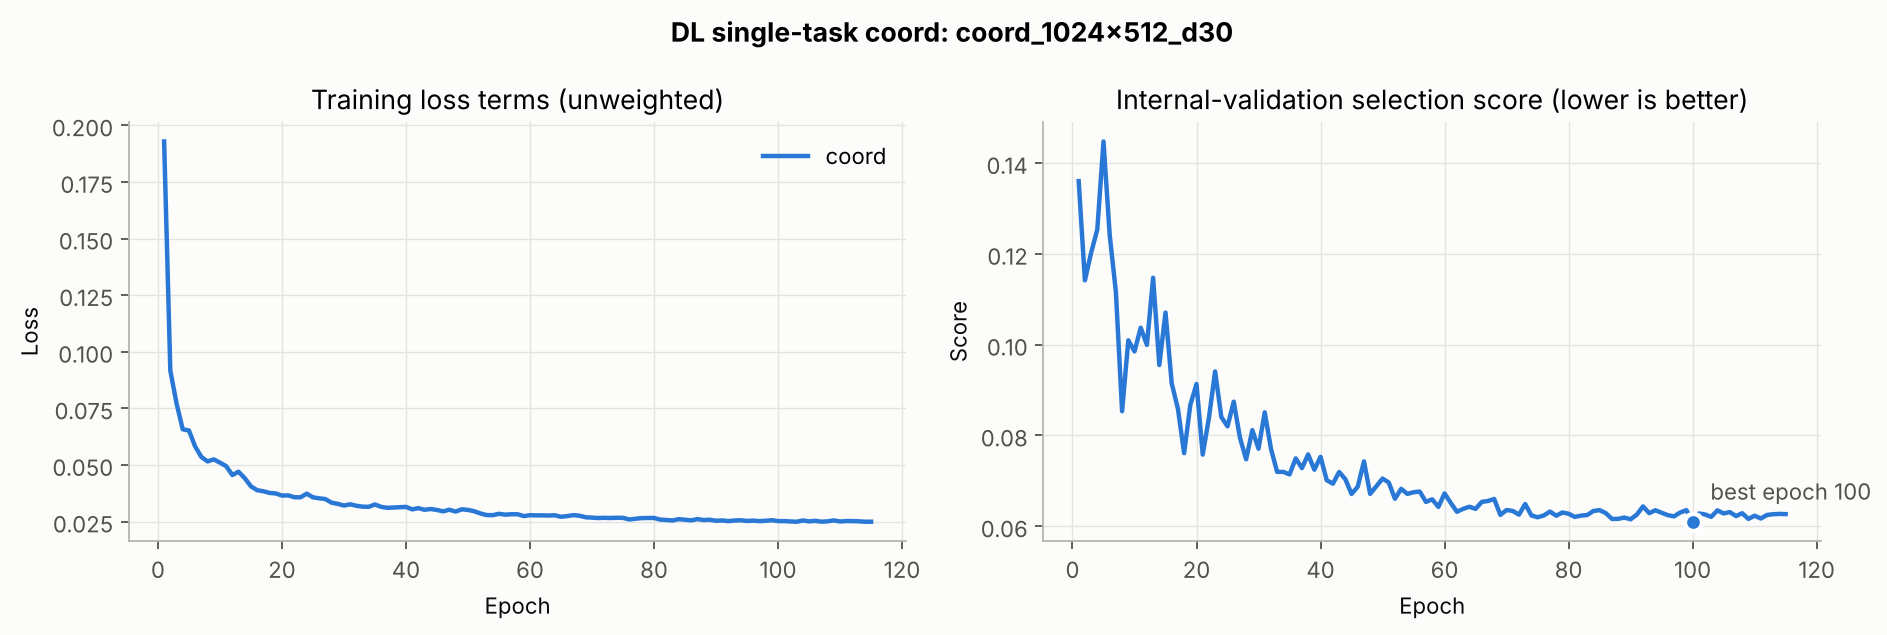

In [4]:
display(Image(filename=str(C.FIGURES_DIR / "dl_04_coordinate_training_history.png")))

## 4. Held-out diagnostic

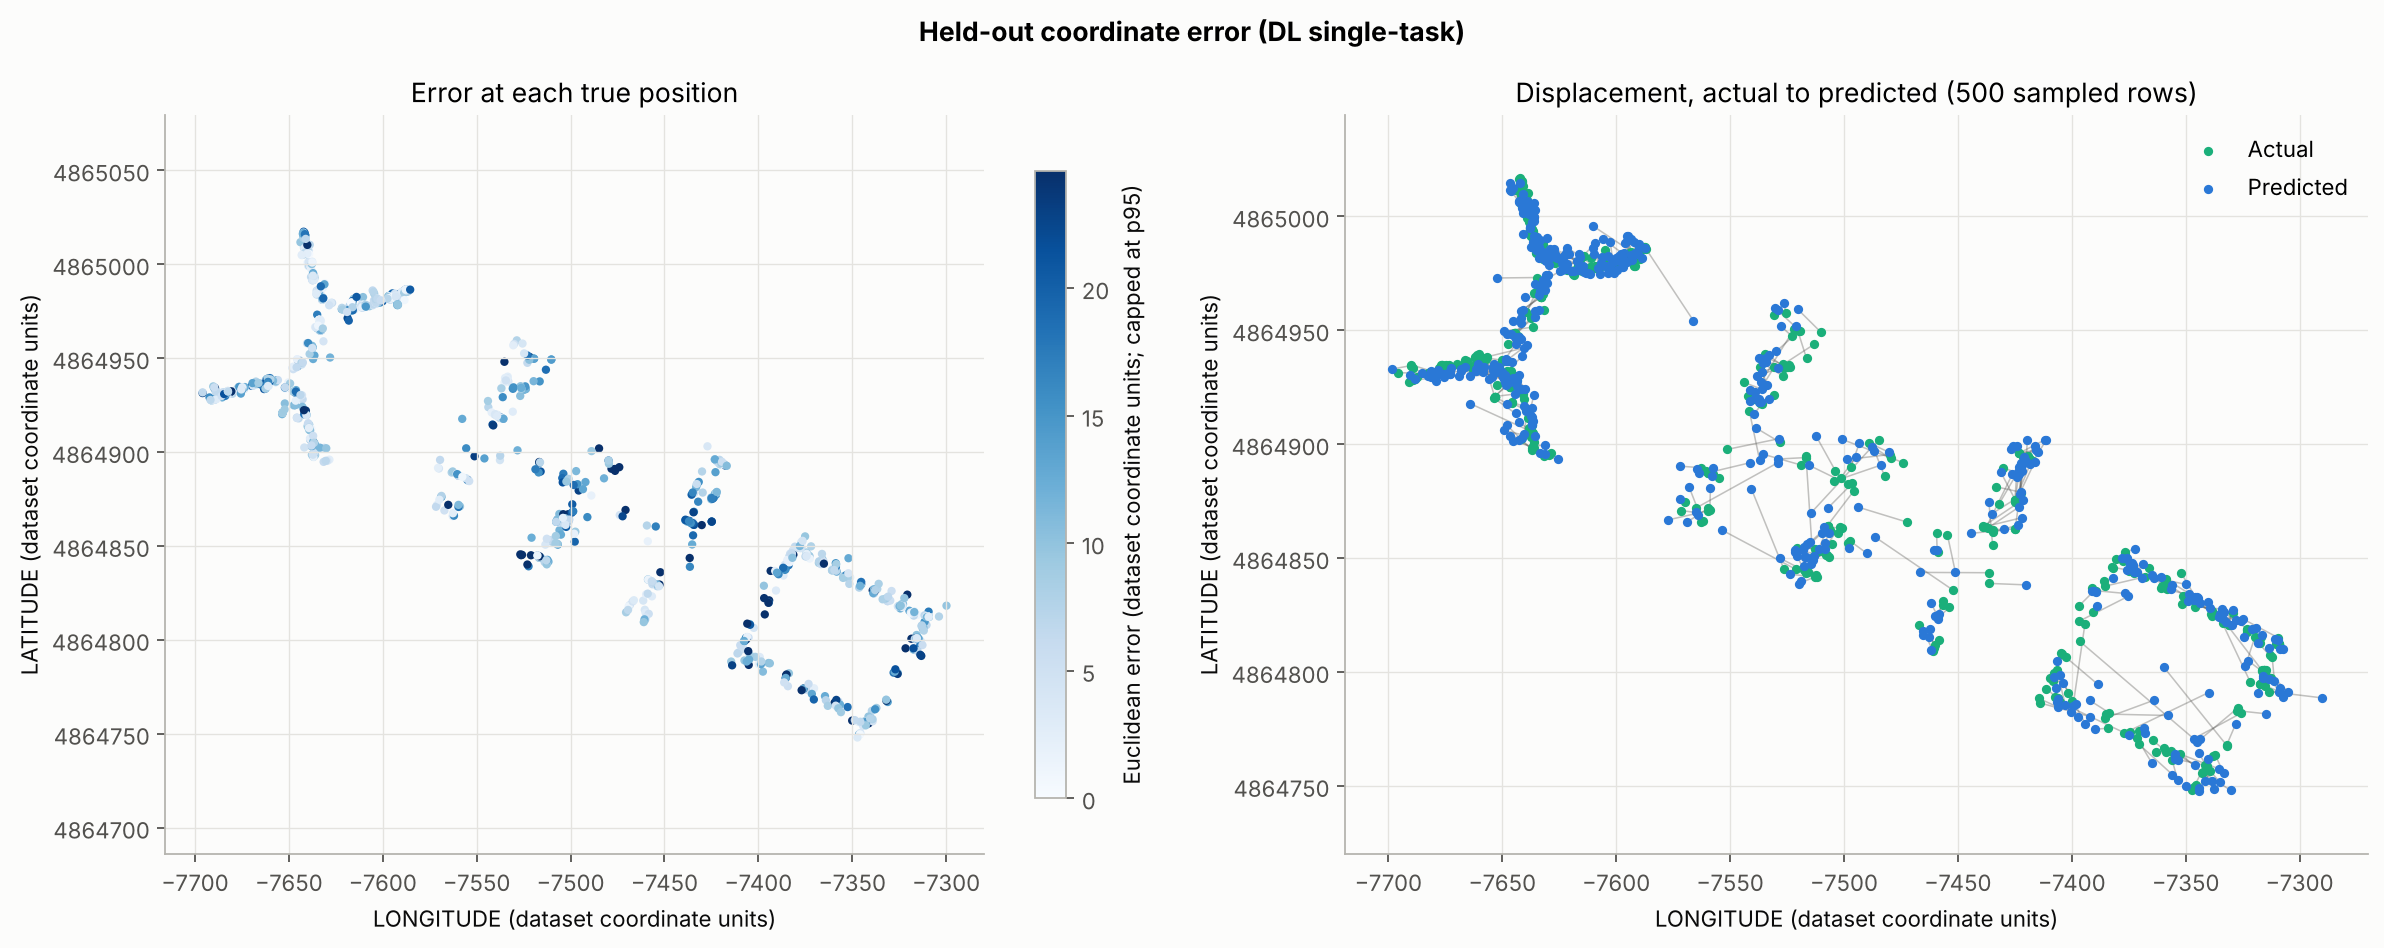

In [5]:
display(Image(filename=str(C.FIGURES_DIR / "dl_04_coordinate_heldout_error_map.png")))

## Conclusion

Outputs: `data/tables/dl_04_coordinate_*.csv`, `data/figures/dl_04_coordinate_*.png` and `models/dl/dl_04_coordinate.pt`. DL_05 compares these single-task results with the multitask model and the AML baseline on identical rows.